Case Study: E-Commerce Customer Segmentation — Apply K-Means and DBSCAN to an RFM (Recency, Frequency, Monetary) dataset from an online retailer. Reduce dimensions with PCA, visualize segments with t-SNE, and derive actionable marketing personas from each cluster.

In [2]:
#DATA HANDLING
import pandas as pd
import numpy as np

#DATA VISUALIZATION
import matplotlib.pyplot as plt
import seaborn as sns

#DATA PREPROCESSING
from sklearn.preprocessing import StandardScaler

#CLUSTERING ALGORITHMS
from sklearn.cluster import KMeans,DBSCAN

#DIMENTIONALITY REDUCTION
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

#EVALUATION METRICS
from sklearn.metrics import silhouette_score

In [7]:
file='/content/online_retail_II.xlsx'

In [8]:
excel=pd.ExcelFile(file)
excel.sheet_names

['Year 2009-2010', 'Year 2010-2011']

In [9]:
df1=pd.read_excel(excel,sheet_name='Year 2009-2010')
df2=pd.read_excel(excel,sheet_name='Year 2010-2011')

In [11]:
df1.shape

(525461, 8)

In [12]:
df2.shape

(541910, 8)

In [13]:
df1.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [14]:
df=pd.concat([df1,df2],ignore_index=True)

In [15]:
df.shape

(1067371, 8)

In [16]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [18]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


Null Value Treatment

In [19]:
df.isnull().sum()

,0
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


In [22]:
df['Description']=df['Description'].fillna("Unknown Product")

In [26]:
df["Customer ID"].isnull().mean() * 100

np.float64(22.766872999172733)

In [27]:
df_clean = df.copy()

In [29]:
df=df.dropna(subset=['Customer ID'])

In [30]:
df.isnull().sum()

,0
Invoice,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
Price,0
Customer ID,0
Country,0


Duplicated Records

In [32]:
df.duplicated().sum()

np.int64(26479)

In [33]:
df=df.drop_duplicates()

In [35]:
df.duplicated().sum()

np.int64(0)

In [36]:
print("Unique Customers:", df['Customer ID'].nunique())

print("Unique Invoices:", df["Invoice"].nunique())

print("Unique Products:", df["StockCode"].nunique())

print("Unique Countries:", df["Country"].nunique())

Unique Customers: 5942
Unique Invoices: 44876
Unique Products: 4646
Unique Countries: 41


In [37]:
avg_invoices = df["Invoice"].nunique() / df["Customer ID"].nunique()

print("Average invoices per customer:", round(avg_invoices, 2))

Average invoices per customer: 7.55


In [38]:
print("First transaction:", df["InvoiceDate"].min())
print("Last transaction:", df["InvoiceDate"].max())

First transaction: 2009-12-01 07:45:00
Last transaction: 2011-12-09 12:50:00


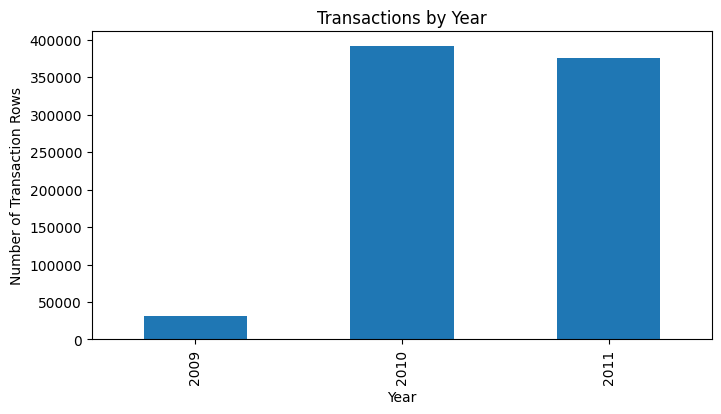

In [39]:
df["InvoiceDate"].dt.year.value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Transactions by Year")
plt.xlabel("Year")
plt.ylabel("Number of Transaction Rows")
plt.show()

Cancelled Invoices

In [40]:
cancelled=df[df['Invoice'].astype(str).str.startswith("C")]

In [42]:
print("Cancelled Transactions : ",len(cancelled))

Cancelled Transactions :  18390


In [43]:
df = df[~df["Invoice"].astype(str).str.startswith("C")]

Removing Invalid Prices and Quantities

In [44]:
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]

In [45]:
print("Dataset shape:", df.shape)
print("Invalid quantities:", (df["Quantity"] <= 0).sum())
print("Invalid prices:", (df["Price"] <= 0).sum())
print("Missing Customer IDs:", df["Customer ID"].isnull().sum())

Dataset shape: (779425, 8)
Invalid quantities: 0
Invalid prices: 0
Missing Customer IDs: 0


RFM(Recency, Frequency, Monetary) Stats

Revenue

In [46]:
df['Revenue']=df['Quantity']*df['Price']

In [47]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


Reference Date for Recency

In [48]:
today = df["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Reference date:", today)

Reference date: 2011-12-10 12:50:00


In [49]:
rfm = df.groupby("Customer ID").agg(

    Recency=("InvoiceDate", lambda x: (today - x.max()).days),

    Frequency=("Invoice", "nunique"),

    Monetary=("Revenue", "sum")

)

In [50]:
rfm.head(10)

,Recency,Frequency,Monetary
Customer ID,,,
12346.0,326,12,77556.46
12347.0,2,8,4921.53
12348.0,75,5,2019.40
12349.0,19,4,4428.69
12350.0,310,1,334.40
12351.0,375,1,300.93
12352.0,36,10,2849.84
12353.0,204,2,406.76
12354.0,232,1,1079.40


In [51]:
rfm.shape

(5878, 3)

In [52]:
rfm.describe()

,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000
mean,201.331916,6.289384,2955.904095
std,209.338707,13.009406,14440.852688
min,1.000000,1.000000,2.950000
25%,26.000000,1.000000,342.280000
50%,96.000000,3.000000,867.740000
75%,380.000000,7.000000,2248.305000
max,739.000000,398.000000,580987.040000


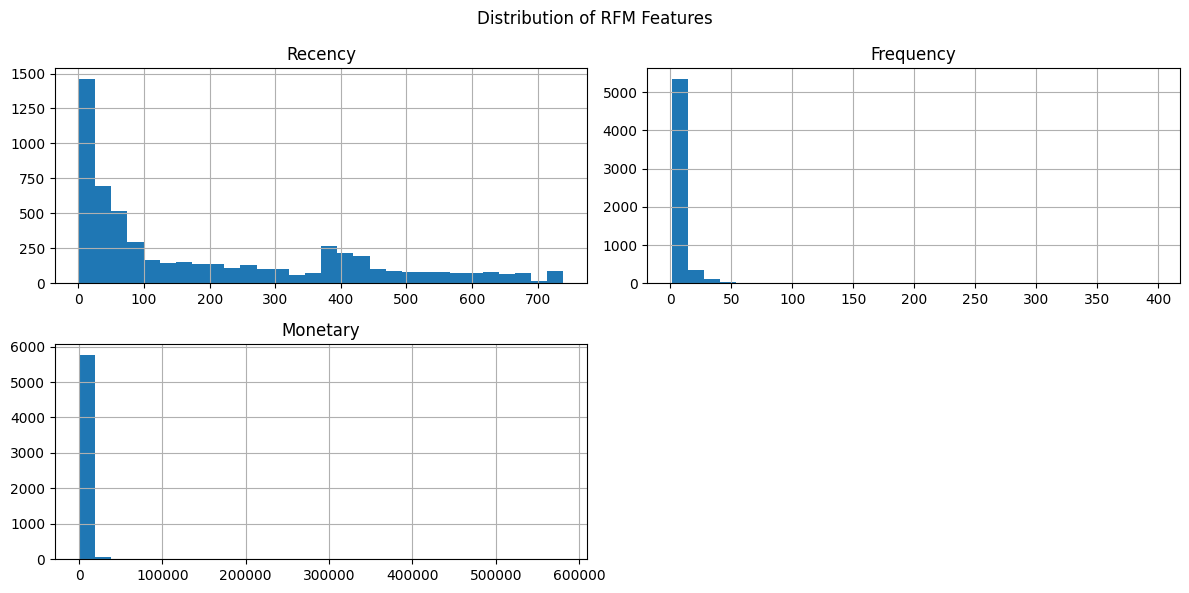

In [53]:
rfm[["Recency", "Frequency", "Monetary"]].hist(
    bins=30,
    figsize=(12, 6)
)

plt.suptitle("Distribution of RFM Features")
plt.tight_layout()
plt.show()

Skewness treatment & Scaling

In [54]:
X = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])

In [55]:
X.head(10)

,Recency,Frequency,Monetary
Customer ID,,,
12346.0,5.789960,2.564949,11.258774
12347.0,1.098612,2.197225,8.501578
12348.0,4.330733,1.791759,7.611051
12349.0,2.995732,1.609438,8.396085
12350.0,5.739793,0.693147,5.815324
12351.0,5.929589,0.693147,5.710195
12352.0,3.610918,2.397895,7.955369
12353.0,5.323010,1.098612,6.010679
12354.0,5.451038,0.693147,6.985087


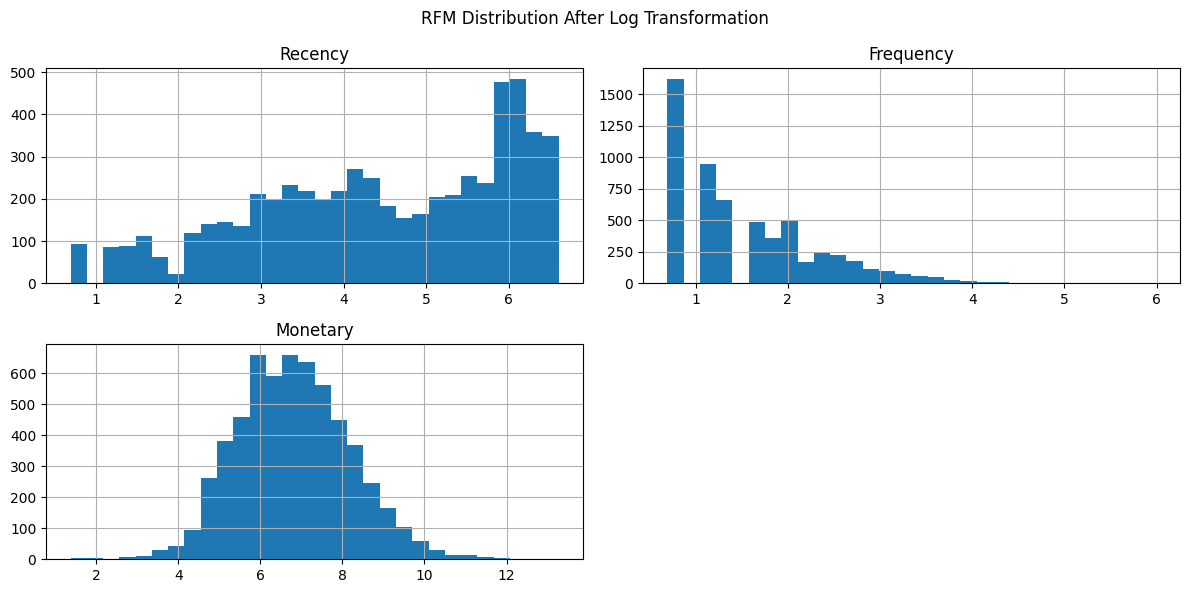

In [56]:
X.hist(bins=30, figsize=(12, 6))

plt.suptitle("RFM Distribution After Log Transformation")
plt.tight_layout()
plt.show()

In [59]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [60]:
print("Mean:", X_scaled.mean(axis=0))
print("Standard Deviation:", X_scaled.std(axis=0))

Mean: [-5.07703214e-16  1.88575479e-16  3.77150959e-16]
Standard Deviation: [1. 1. 1.]


Clustering


In [61]:
wcss=[]
for k in range(2,11):
  kmeans = KMeans(n_clusters=k,
                random_state=42,
                n_init=10)
  kmeans.fit(X_scaled)
  wcss.append(kmeans.inertia_)

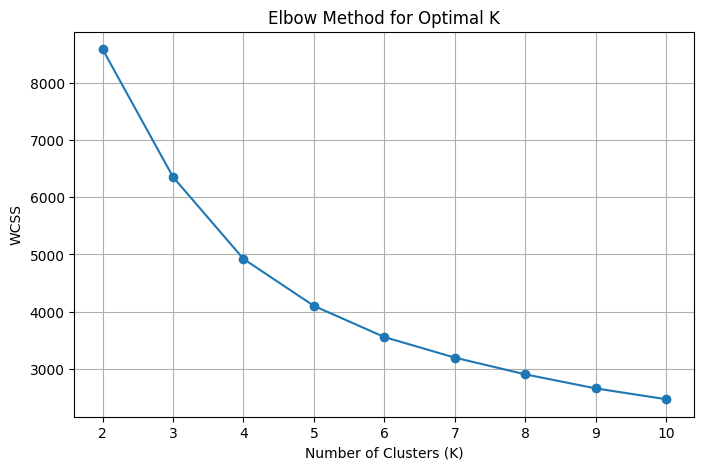

In [114]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), wcss, marker='o')

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(2, 11))
plt.grid(True)

plt.savefig(
    "pca_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [63]:
silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.4386
K = 3, Silhouette Score = 0.3477
K = 4, Silhouette Score = 0.3650
K = 5, Silhouette Score = 0.3425
K = 6, Silhouette Score = 0.3348
K = 7, Silhouette Score = 0.3066
K = 8, Silhouette Score = 0.3033
K = 9, Silhouette Score = 0.2925
K = 10, Silhouette Score = 0.2905


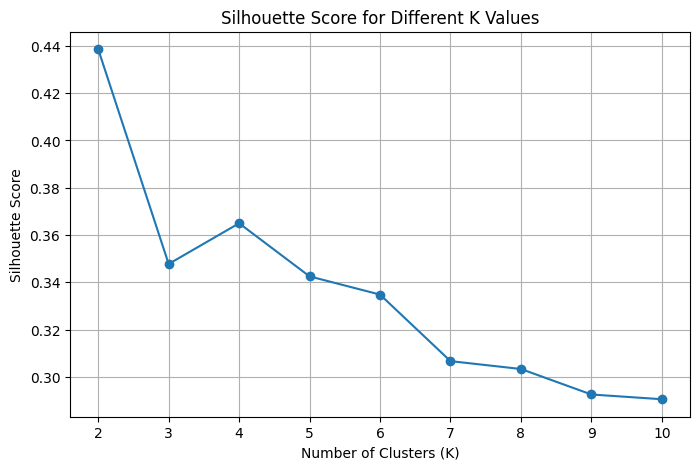

In [113]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)

plt.savefig(
    "pca_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [65]:
# Train K-Means with K=2
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)

labels_2 = kmeans_2.fit_predict(X_scaled)

# Train K-Means with K=4
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)

labels_4 = kmeans_4.fit_predict(X_scaled)

In [66]:
print("K = 2")
print(pd.Series(labels_2).value_counts().sort_index())

print("\nK = 4")
print(pd.Series(labels_4).value_counts().sort_index())

K = 2
0    3558
1    2320
Name: count, dtype: int64

K = 4
0    1973
1    1250
2    1196
3    1459
Name: count, dtype: int64


In [67]:
# Create a copy of original RFM data
comparison = rfm.copy()

comparison["Cluster_K2"] = labels_2
comparison["Cluster_K4"] = labels_4

print("Customer profiles for K=2")

display(
    comparison.groupby("Cluster_K2")[
        ["Recency", "Frequency", "Monetary"]
    ].mean().round(2)
)

print("Customer profiles for K=4")

display(
    comparison.groupby("Cluster_K4")[
        ["Recency", "Frequency", "Monetary"]
    ].mean().round(2)
)

Customer profiles for K=2


,Recency,Frequency,Monetary
Cluster_K2,,,
0,299.65,2.10,614.34
1,50.56,12.72,6546.97


Customer profiles for K=4


,Recency,Frequency,Monetary
Cluster_K4,,,
0,394.95,1.38,317.08
1,28.30,3.05,857.49
2,27.71,19.28,10731.16
3,230.07,5.06,1948.50


In [68]:
print("Cluster sizes:")

print(
    comparison["Cluster_K4"]
    .value_counts()
    .sort_index()
)

Cluster sizes:
Cluster_K4
0    1973
1    1250
2    1196
3    1459
Name: count, dtype: int64


In [69]:
cluster_percent = (
    comparison["Cluster_K4"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(cluster_percent.round(2))

Cluster_K4
0    33.57
1    21.27
2    20.35
3    24.82
Name: proportion, dtype: float64


k=4

In [70]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(X_scaled)


In [71]:
print(rfm["Cluster"].value_counts().sort_index())

Cluster
0    1973
1    1250
2    1196
3    1459
Name: count, dtype: int64


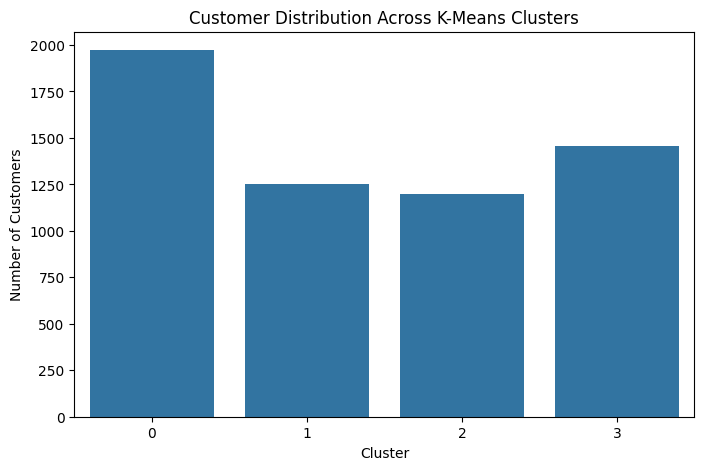

In [72]:
plt.figure(figsize=(8, 5))

sns.countplot(data=rfm, x="Cluster")

plt.title("Customer Distribution Across K-Means Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.show()

In [73]:
cluster_profile = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)

display(cluster_profile)

,Recency,Frequency,Monetary
Cluster,,,
0,394.95,1.38,317.08
1,28.30,3.05,857.49
2,27.71,19.28,10731.16
3,230.07,5.06,1948.50


In [74]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)


In [75]:
print("Explained variance ratio:", pca.explained_variance_ratio_)

print(
    "Total variance retained:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

Explained variance ratio: [0.76356725 0.18744412]
Total variance retained: 95.1 %


In [76]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"],
    index=rfm.index
)

pca_df["Cluster"] = rfm["Cluster"]

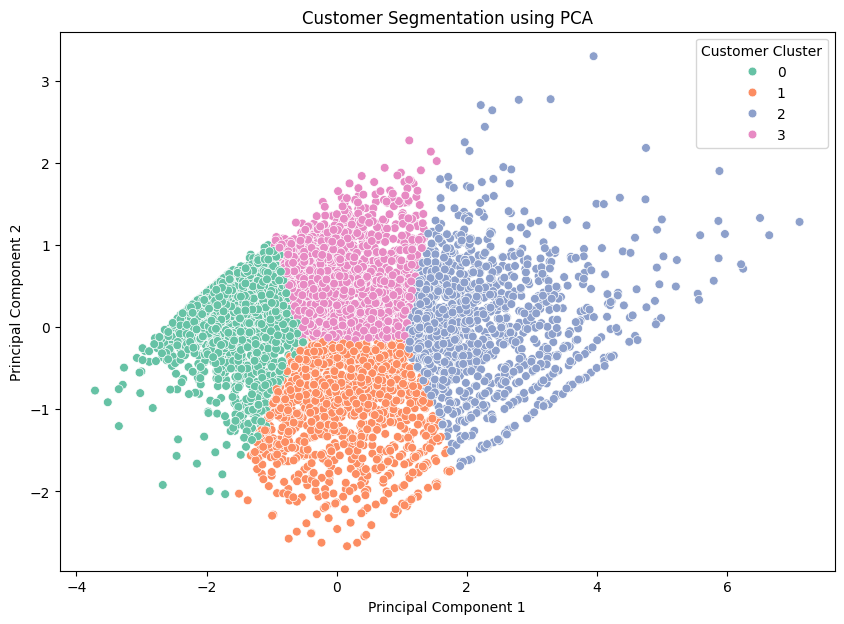

In [115]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    s=40
)

plt.title("Customer Segmentation using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Cluster")

plt.savefig(
    "pca_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [78]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

In [79]:
tsne_df = pd.DataFrame(
    X_tsne,
    columns=["TSNE1", "TSNE2"],
    index=rfm.index
)

tsne_df["Cluster"] = rfm["Cluster"]

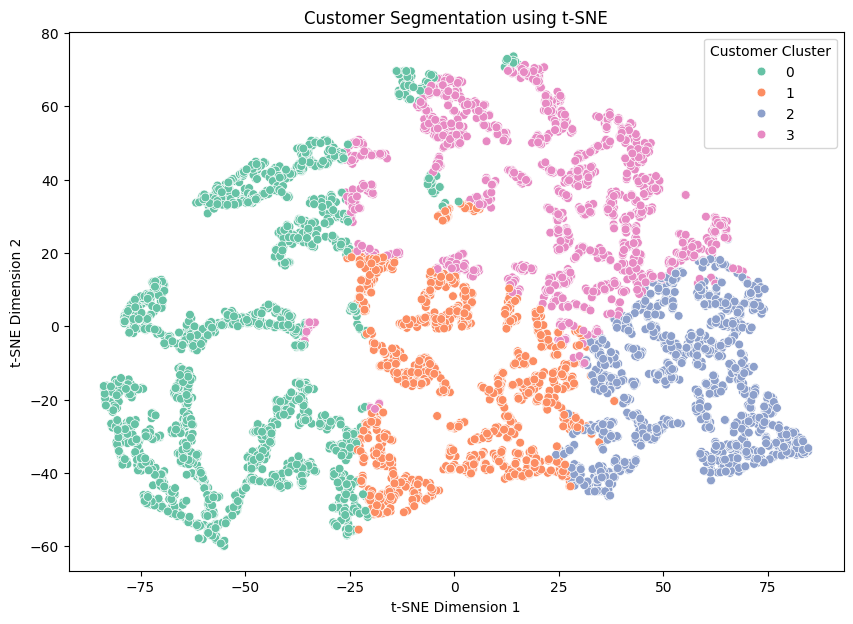

In [116]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=tsne_df,
    x="TSNE1",
    y="TSNE2",
    hue="Cluster",
    palette="Set2",
    s=40
)

plt.title("Customer Segmentation using t-SNE")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Customer Cluster")

plt.savefig(
    "tsne_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [81]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

rfm["DBSCAN_Cluster"] = dbscan_labels

In [82]:
n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)

n_noise = list(dbscan_labels).count(-1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print("Noise percentage:", round(n_noise / len(dbscan_labels) * 100, 2), "%")

Number of clusters: 2
Number of noise points: 64
Noise percentage: 1.09 %


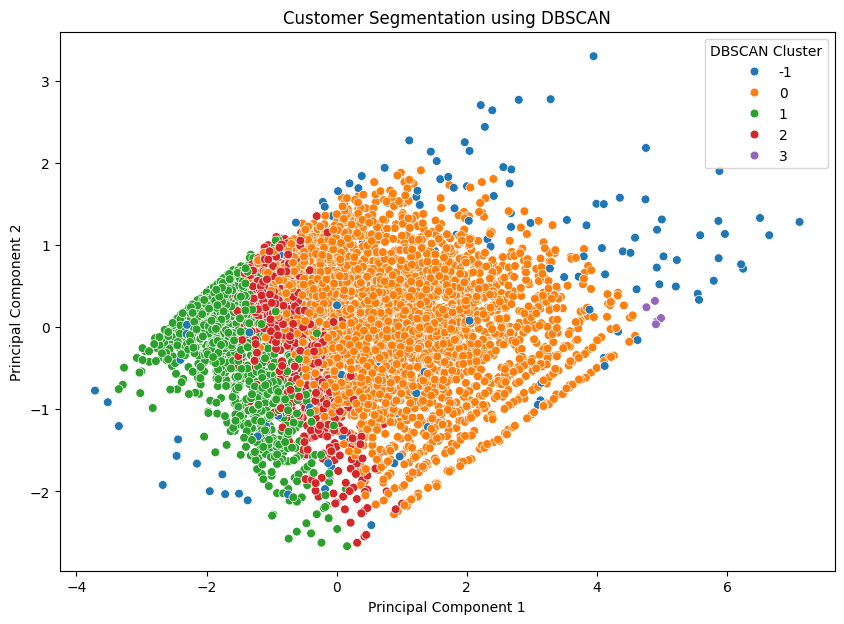

In [117]:
dbscan_pca_df = pca_df.copy()

dbscan_pca_df["DBSCAN_Cluster"] = dbscan_labels

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=dbscan_pca_df,
    x="PC1",
    y="PC2",
    hue="DBSCAN_Cluster",
    palette="tab10",
    s=40
)

plt.title("Customer Segmentation using DBSCAN")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="DBSCAN Cluster")

plt.savefig(
    "dbscan_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

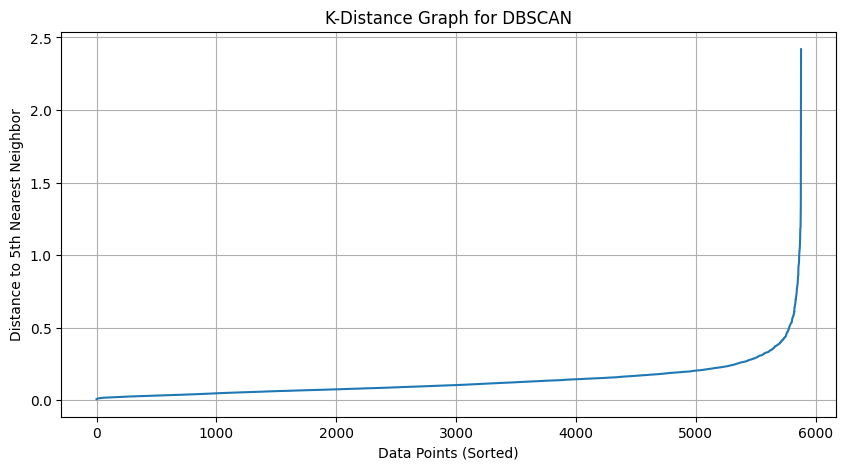

In [84]:
from sklearn.neighbors import NearestNeighbors
neighbors = NearestNeighbors(n_neighbors=5)

neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

distances = np.sort(distances[:, 4])

plt.figure(figsize=(10, 5))

plt.plot(distances)

plt.title("K-Distance Graph for DBSCAN")
plt.xlabel("Data Points (Sorted)")
plt.ylabel("Distance to 5th Nearest Neighbor")

plt.grid(True)
plt.show()

In [85]:
eps_values = [0.30, 0.35, 0.40, 0.45, 0.50]

for eps in eps_values:

    labels = DBSCAN(
        eps=eps,
        min_samples=5
    ).fit_predict(X_scaled)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    n_noise = np.sum(labels == -1)

    noise_percentage = (n_noise / len(labels)) * 100

    print(f"\neps = {eps}")
    print("Number of clusters:", n_clusters)
    print("Noise points:", n_noise)
    print("Noise percentage:", round(noise_percentage, 2), "%")


eps = 0.3
Number of clusters: 7
Noise points: 224
Noise percentage: 3.81 %

eps = 0.35
Number of clusters: 4
Noise points: 142
Noise percentage: 2.42 %

eps = 0.4
Number of clusters: 3
Noise points: 105
Noise percentage: 1.79 %

eps = 0.45
Number of clusters: 2
Noise points: 71
Noise percentage: 1.21 %

eps = 0.5
Number of clusters: 2
Noise points: 64
Noise percentage: 1.09 %


In [86]:
dbscan = DBSCAN(
    eps=0.35,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

rfm["DBSCAN_Cluster"] = dbscan_labels

In [87]:
print("DBSCAN Cluster Distribution:")

print(
    rfm["DBSCAN_Cluster"]
    .value_counts()
    .sort_index()
)

DBSCAN Cluster Distribution:
DBSCAN_Cluster
-1     142
 0    3200
 1    1601
 2     930
 3       5
Name: count, dtype: int64


In [88]:
cluster_percent = (
    rfm["DBSCAN_Cluster"]
    .value_counts(normalize=True) * 100
)

print(cluster_percent.round(2))

DBSCAN_Cluster
 0    54.44
 1    27.24
 2    15.82
-1     2.42
 3     0.09
Name: proportion, dtype: float64


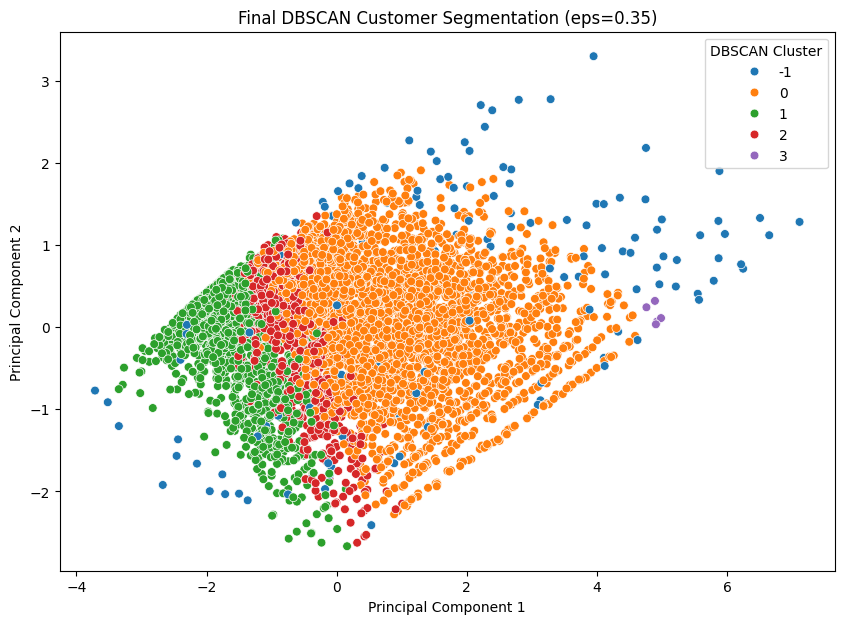

In [89]:
dbscan_pca_df = pca_df.copy()

dbscan_pca_df["DBSCAN_Cluster"] = dbscan_labels

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=dbscan_pca_df,
    x="PC1",
    y="PC2",
    hue="DBSCAN_Cluster",
    palette="tab10",
    s=40
)

plt.title("Final DBSCAN Customer Segmentation (eps=0.35)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="DBSCAN Cluster")

plt.show()

In [90]:
# Remove noise points for evaluation
mask = dbscan_labels != -1

X_dbscan = X_scaled[mask]
labels_dbscan = dbscan_labels[mask]

score = silhouette_score(
    X_dbscan,
    labels_dbscan
)

print("DBSCAN Silhouette Score:", round(score, 4))

DBSCAN Silhouette Score: 0.1201


In [91]:
print(
    rfm["DBSCAN_Cluster"]
    .value_counts()
    .sort_index()
)

DBSCAN_Cluster
-1     142
 0    3200
 1    1601
 2     930
 3       5
Name: count, dtype: int64


In [92]:
dbscan_profile = rfm.groupby("DBSCAN_Cluster").agg({
    "Recency": ["mean", "median"],
    "Frequency": ["mean", "median"],
    "Monetary": ["mean", "median"]
}).round(2)

display(dbscan_profile)

Recency        Frequency         Monetary          
                  mean median      mean median      mean    median
DBSCAN_Cluster                                                    
-1              145.40   33.0     38.46   10.5  40336.38  11650.26
 0              113.57   46.0      8.66    6.0   3228.94   1828.72
 1              357.24  388.0      1.00    1.0    315.11    228.96
 2              244.52  211.5      2.00    2.0    636.16    514.46
 3                1.40    1.0     68.80   70.0  43663.57  39918.19

In [93]:
cluster_distribution = (
    rfm["DBSCAN_Cluster"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(cluster_distribution.round(2))

DBSCAN_Cluster
-1     2.42
 0    54.44
 1    27.24
 2    15.82
 3     0.09
Name: proportion, dtype: float64


In [94]:
mask = dbscan_labels != -1

kmeans_score_comparable = silhouette_score(
    X_scaled[mask],
    labels_4[mask]
)

dbscan_score = silhouette_score(
    X_scaled[mask],
    dbscan_labels[mask]
)

print("K-Means (same customers):", round(kmeans_score_comparable, 4))
print("DBSCAN:", round(dbscan_score, 4))

K-Means (same customers): 0.3746
DBSCAN: 0.1201


K-Means is the better primary segmentation model for this dataset.

In [95]:
final_profile = rfm.groupby("Cluster").agg(
    Customer_Count=("Recency", "count"),
    Recency_Mean=("Recency", "mean"),
    Recency_Median=("Recency", "median"),
    Frequency_Mean=("Frequency", "mean"),
    Frequency_Median=("Frequency", "median"),
    Monetary_Mean=("Monetary", "mean"),
    Monetary_Median=("Monetary", "median")
).round(2)

final_profile["Percentage"] = (
    final_profile["Customer_Count"] / len(rfm) * 100
).round(2)

display(final_profile)

,Customer_Count,Recency_Mean,Recency_Median,Frequency_Mean,Frequency_Median,Monetary_Mean,Monetary_Median,Percentage
Cluster,,,,,,,,
0,1973,394.95,402.0,1.38,1.0,317.08,273.31,33.57
1,1250,28.30,24.0,3.05,3.0,857.49,734.12,21.27
2,1196,27.71,17.0,19.28,13.0,10731.16,4986.12,20.35
3,1459,230.07,186.0,5.06,4.0,1948.50,1450.04,24.82


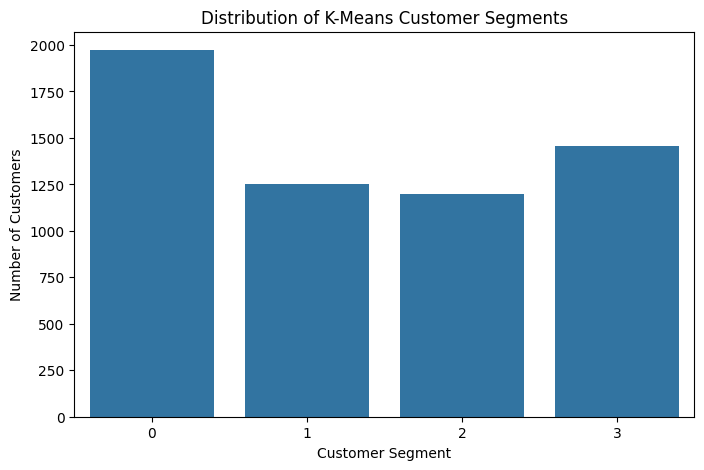

In [96]:
plt.figure(figsize=(8, 5))

sns.countplot(data=rfm, x="Cluster")

plt.title("Distribution of K-Means Customer Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.show()

In [97]:
rfm.to_csv("final_customer_segmentation.csv")

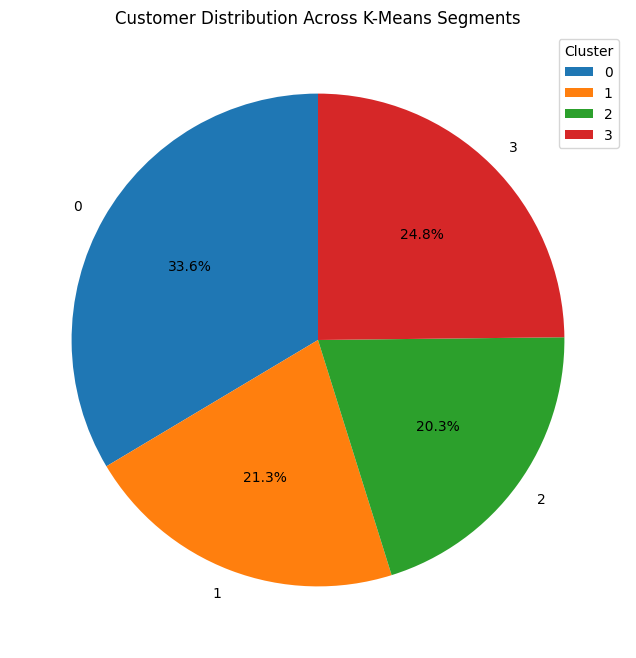

In [98]:
plt.figure(figsize=(8, 8))

plt.pie(
    final_profile["Customer_Count"],
    labels=final_profile.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Distribution Across K-Means Segments")
plt.legend(title="Cluster", loc="best")

plt.show()

In [99]:
personas = {
    0: "Dormant Customers",
    1: "Potential Loyalists",
    2: "Champions / VIPs",
    3: "At-Risk Customers"
}

strategies = {
    0: "Win-back campaigns and discounts",
    1: "Loyalty points and cross-selling",
    2: "VIP rewards and exclusive offers",
    3: "Personalized reactivation campaigns"
}

final_profile["Persona"] = final_profile.index.map(personas)
final_profile["Marketing_Strategy"] = final_profile.index.map(strategies)

display(final_profile)

,Customer_Count,Recency_Mean,Recency_Median,Frequency_Mean,Frequency_Median,Monetary_Mean,Monetary_Median,Percentage,Persona,Marketing_Strategy
Cluster,,,,,,,,,,
0,1973,394.95,402.0,1.38,1.0,317.08,273.31,33.57,Dormant Customers,Win-back campaigns and discounts
1,1250,28.30,24.0,3.05,3.0,857.49,734.12,21.27,Potential Loyalists,Loyalty points and cross-selling
2,1196,27.71,17.0,19.28,13.0,10731.16,4986.12,20.35,Champions / VIPs,VIP rewards and exclusive offers
3,1459,230.07,186.0,5.06,4.0,1948.50,1450.04,24.82,At-Risk Customers,Personalized reactivation campaigns


In [100]:
# Save customer-level segmentation
rfm.to_csv("final_customer_segmentation.csv")

# Save cluster-level profiles
final_profile.to_csv("final_cluster_profiles.csv")

# Save DBSCAN profiles
dbscan_profile.to_csv("dbscan_cluster_profiles.csv")

Conclusion

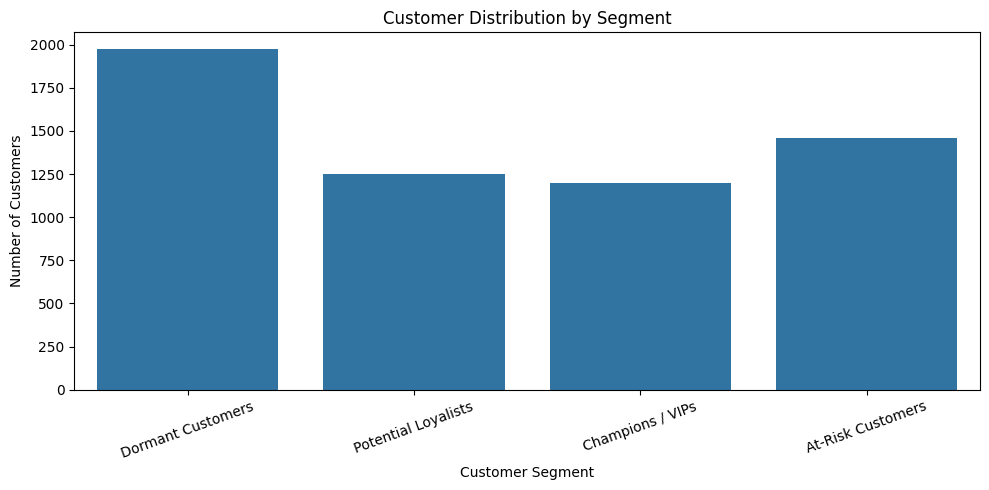

In [101]:
personas = {
    0: "Dormant Customers",
    1: "Potential Loyalists",
    2: "Champions / VIPs",
    3: "At-Risk Customers"
}

rfm["Persona"] = rfm["Cluster"].map(personas)

plt.figure(figsize=(10, 5))

sns.countplot(
    data=rfm,
    x="Persona",
    order=list(personas.values())
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

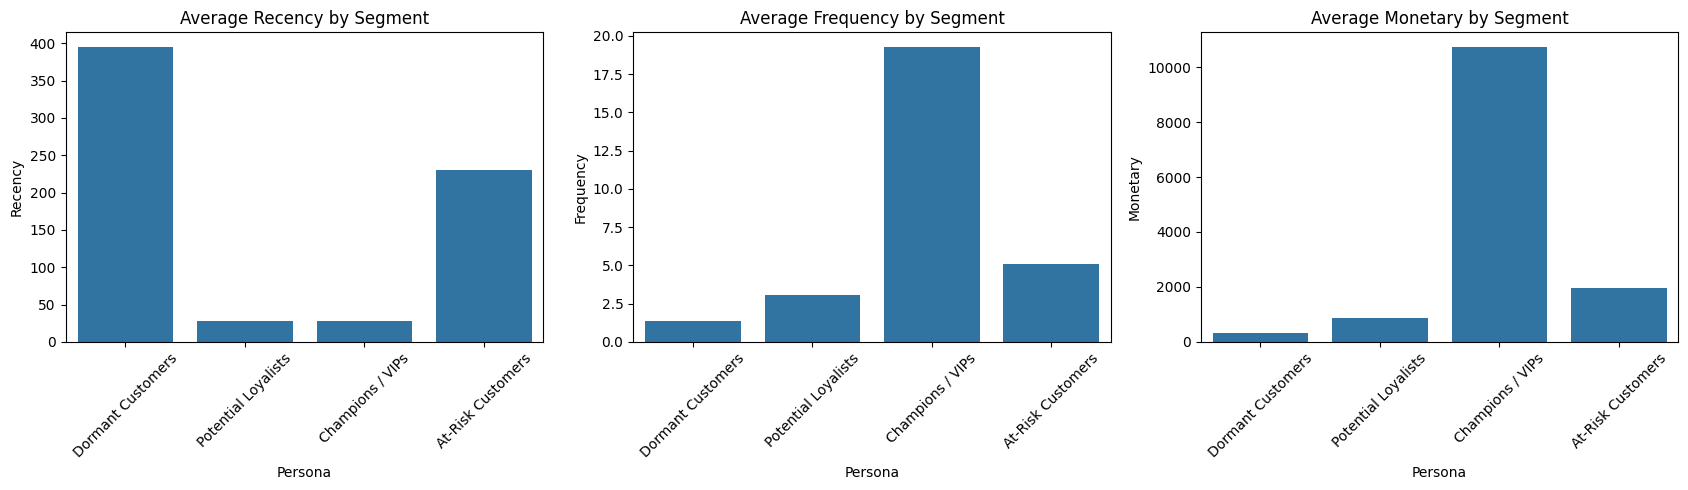

In [102]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = ["Recency", "Frequency", "Monetary"]

for i, metric in enumerate(metrics):
    sns.barplot(
        data=rfm,
        x="Persona",
        y=metric,
        estimator="mean",
        errorbar=None,
        order=list(personas.values()),
        ax=axes[i]
    )

    axes[i].set_title(f"Average {metric} by Segment")
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

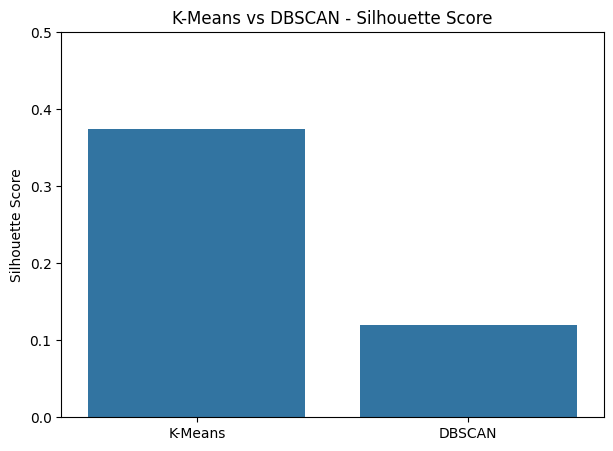

In [103]:
models = ["K-Means", "DBSCAN"]
scores = [0.3746, 0.1201]

plt.figure(figsize=(7, 5))

sns.barplot(x=models, y=scores)

plt.title("K-Means vs DBSCAN - Silhouette Score")
plt.ylabel("Silhouette Score")
plt.ylim(0, 0.5)

plt.show()

In [104]:
revenue_by_segment = rfm.groupby("Persona")["Monetary"].sum()

revenue_percentage = (
    revenue_by_segment / revenue_by_segment.sum() * 100
).round(2)

display(revenue_percentage.sort_values(ascending=False))

,Monetary
Persona,
Champions / VIPs,73.87
At-Risk Customers,16.36
Potential Loyalists,6.17
Dormant Customers,3.60


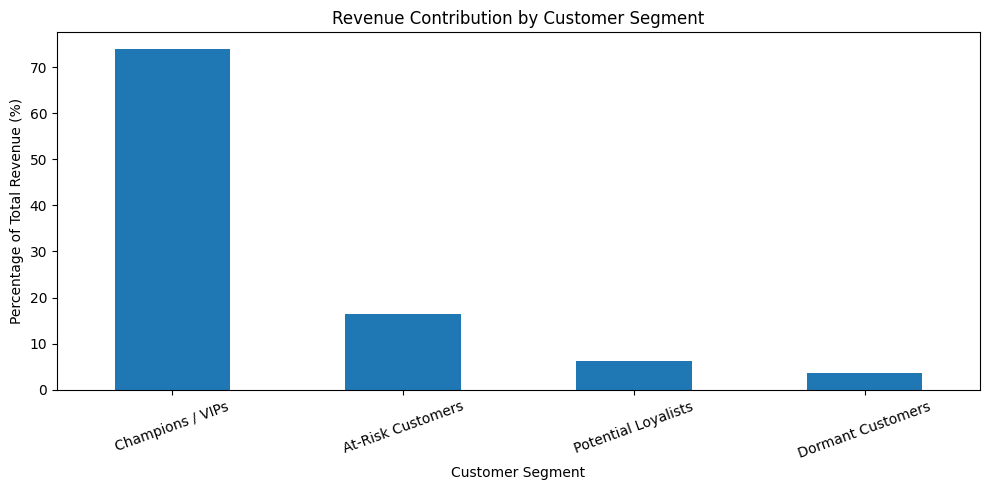

In [105]:
plt.figure(figsize=(10, 5))

revenue_percentage.sort_values(ascending=False).plot(
    kind="bar"
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Percentage of Total Revenue (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [106]:
rfm.to_csv("customer_segmentation_final.csv")

final_profile.to_csv("customer_segment_profiles.csv")

print("Files exported successfully!")

Files exported successfully!


In [107]:
from google.colab import files

files.download("customer_segmentation_final.csv")
files.download("customer_segment_profiles.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

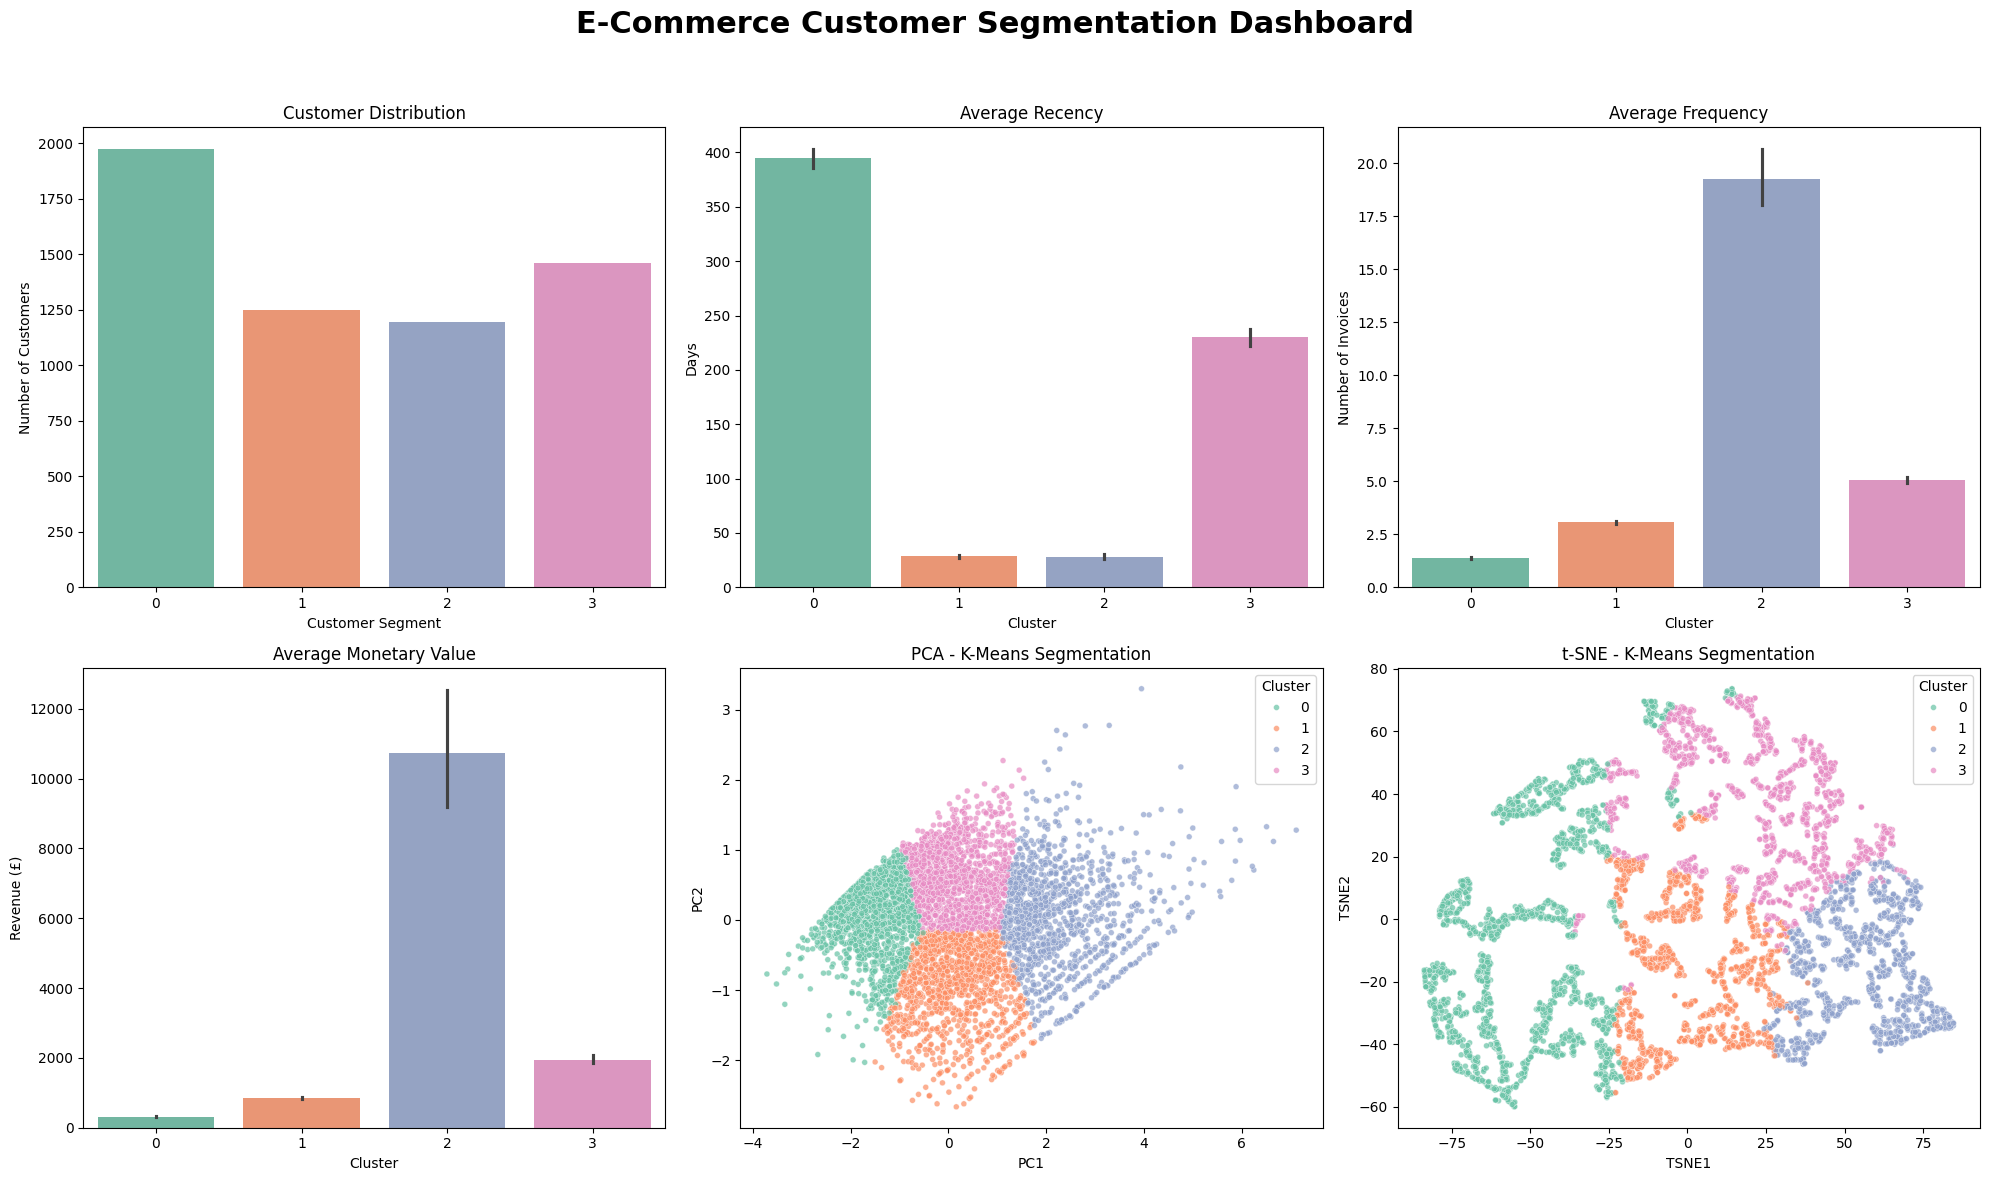

In [109]:

# ==========================================
# E-COMMERCE CUSTOMER SEGMENTATION DASHBOARD
# ==========================================

fig, axes = plt.subplots(2, 3, figsize=(20, 12))

fig.suptitle(
    "E-Commerce Customer Segmentation Dashboard",
    fontsize=22,
    fontweight="bold"
)

# 1. Customer Distribution
sns.countplot(
    data=rfm,
    x="Cluster",
    hue="Cluster",
    palette="Set2",
    legend=False,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Customer Distribution")
axes[0, 0].set_xlabel("Customer Segment")
axes[0, 0].set_ylabel("Number of Customers")

# 2. Recency
sns.barplot(
    data=rfm,
    x="Cluster",
    y="Recency",
    hue="Cluster",
    palette="Set2",
    legend=False,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Average Recency")
axes[0, 1].set_ylabel("Days")

# 3. Frequency
sns.barplot(
    data=rfm,
    x="Cluster",
    y="Frequency",
    hue="Cluster",
    palette="Set2",
    legend=False,
    ax=axes[0, 2]
)

axes[0, 2].set_title("Average Frequency")
axes[0, 2].set_ylabel("Number of Invoices")

# 4. Monetary
sns.barplot(
    data=rfm,
    x="Cluster",
    y="Monetary",
    hue="Cluster",
    palette="Set2",
    legend=False,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Average Monetary Value")
axes[1, 0].set_ylabel("Revenue (£)")

# 5. PCA Visualization
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    s=18,
    alpha=0.7,
    ax=axes[1, 1]
)

axes[1, 1].set_title("PCA - K-Means Segmentation")

# 6. t-SNE Visualization
sns.scatterplot(
    data=tsne_df,
    x="TSNE1",
    y="TSNE2",
    hue="Cluster",
    palette="Set2",
    s=18,
    alpha=0.7,
    ax=axes[1, 2]
)

axes[1, 2].set_title("t-SNE - K-Means Segmentation")

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "customer_segmentation_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [110]:
from google.colab import files

files.download("customer_segmentation_dashboard.png")
files.download("customer_segmentation_final.csv")
files.download("final_cluster_profiles.csv")
files.download("dbscan_cluster_profiles.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>